# Used Cars Price Predictions

project aims to develop a Machine Learning-based regression model to estimate the selling price of pre-owned cars based on various vehicle characteristics.

The project uses the CarDekho Used Car Dataset and applies data analysis, data preprocessing, feature engineering and regression techniques to identify the factors influencing used car prices and build a predictive model.

# Expected Outcome

The final outcome is a trained Machine Learning regression model capable of estimating used car selling prices based on vehicle characteristics.

In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load dataset
df = pd.read_csv("/content/CAR DETAILS FROM CAR DEKHO.csv")

# Display first five records
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## Understand the dataset

In [4]:
df.shape

(4340, 8)

In [5]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [7]:
df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [8]:
df.describe(include='object')

,name,fuel,seller_type,transmission,owner
count,4340,4340,4340,4340,4340
unique,1491,5,3,2,5
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner
freq,69,2153,3244,3892,2832


In [9]:
df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


In [10]:
df.duplicated().sum()

np.int64(763)

In [11]:
for column in df.columns:
    print(f"{column}: {df[column].nunique()} unique values")

name: 1491 unique values
year: 27 unique values
selling_price: 445 unique values
km_driven: 770 unique values
fuel: 5 unique values
seller_type: 3 unique values
transmission: 2 unique values
owner: 5 unique values


## Identify Features and Target Variable

In [12]:
# Independent variables
X = df.drop('selling_price', axis=1)

# Dependent variable
y = df['selling_price']

print("Input features:", X.shape)
print("Target variable:", y.shape)

Input features: (4340, 7)
Target variable: (4340,)


In [13]:
X.head()

,name,year,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,141000,Diesel,Individual,Manual,Second Owner


In [14]:
y.head()

,selling_price
0,60000
1,135000
2,600000
3,250000
4,450000


## EDA Process

### univariate Analysis

### Numerical feature analysis

In [15]:
numerical_cols = df.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(numerical_cols)

Numerical Columns:
Index(['year', 'selling_price', 'km_driven'], dtype='object')


In [16]:
df[numerical_cols].describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


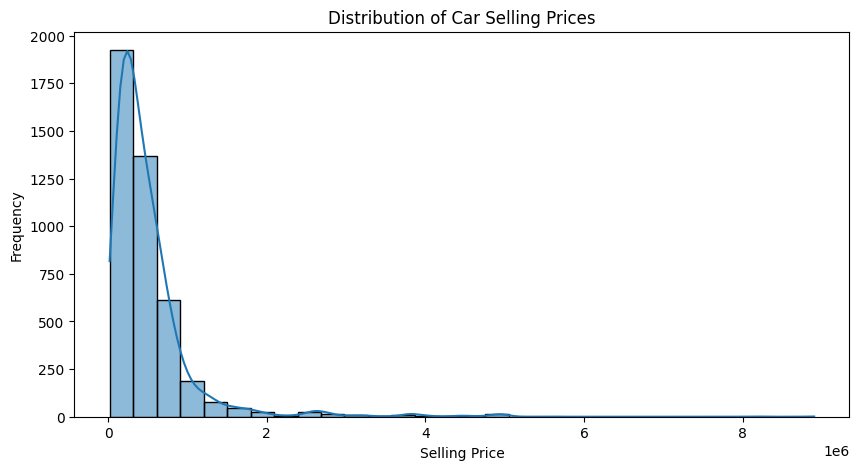

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['selling_price'],
    bins=30,
    kde=True
)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")

plt.show()

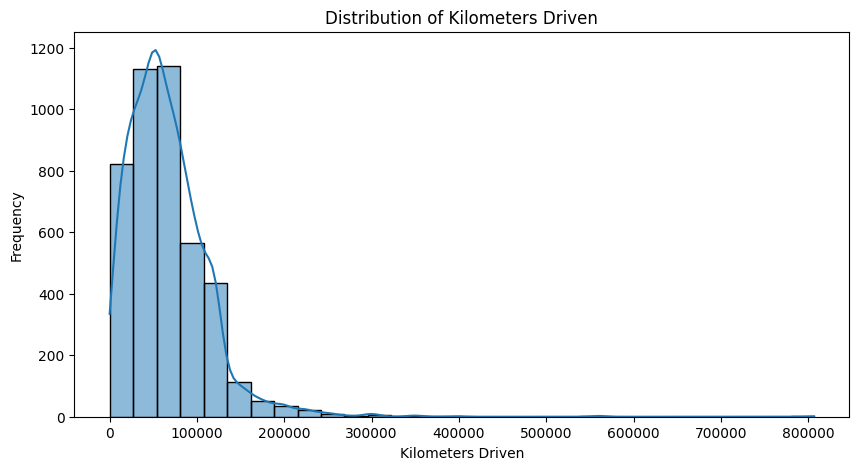

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['km_driven'],
    bins=30,
    kde=True
)

plt.title("Distribution of Kilometers Driven")
plt.xlabel("Kilometers Driven")
plt.ylabel("Frequency")

plt.show()

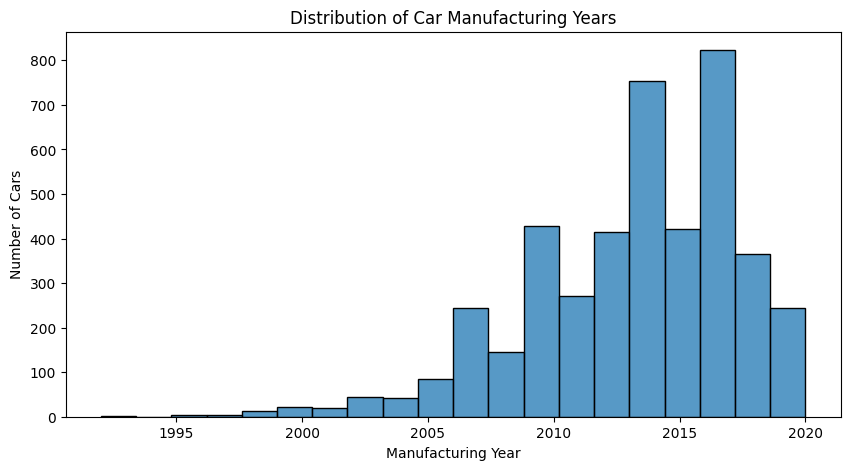

In [19]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['year'],
    bins=20,
    kde=False
)

plt.title("Distribution of Car Manufacturing Years")
plt.xlabel("Manufacturing Year")
plt.ylabel("Number of Cars")

plt.show()

### Categorical feature analysis

In [20]:
categorical_cols = df.select_dtypes(
    include='object'
).columns

print("Categorical Columns:")
print(categorical_cols)

Categorical Columns:
Index(['name', 'fuel', 'seller_type', 'transmission', 'owner'], dtype='object')


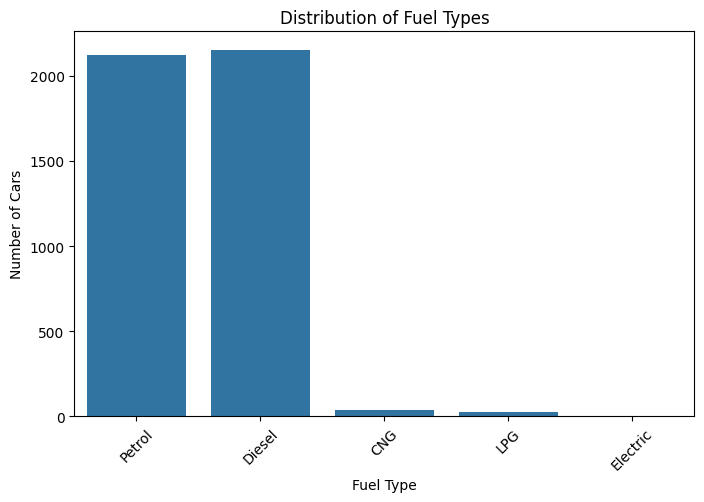

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='fuel'
)

plt.title("Distribution of Fuel Types")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")

plt.xticks(rotation=45)

plt.show()

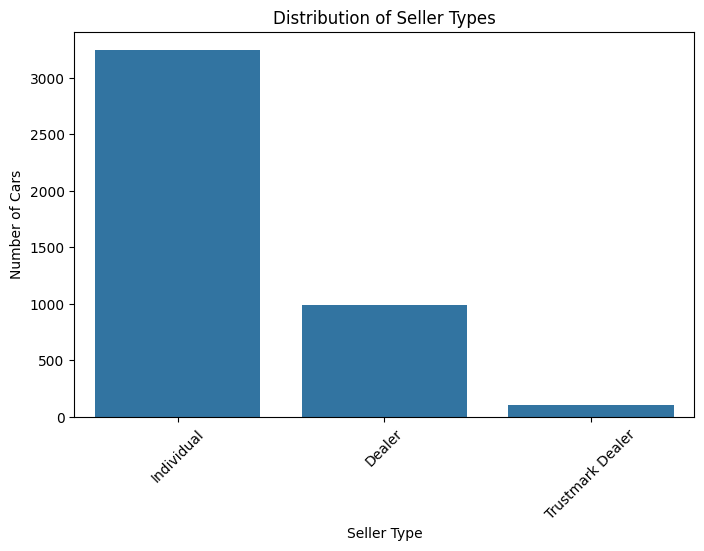

In [22]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='seller_type'
)

plt.title("Distribution of Seller Types")
plt.xlabel("Seller Type")
plt.ylabel("Number of Cars")

plt.xticks(rotation=45)

plt.show()

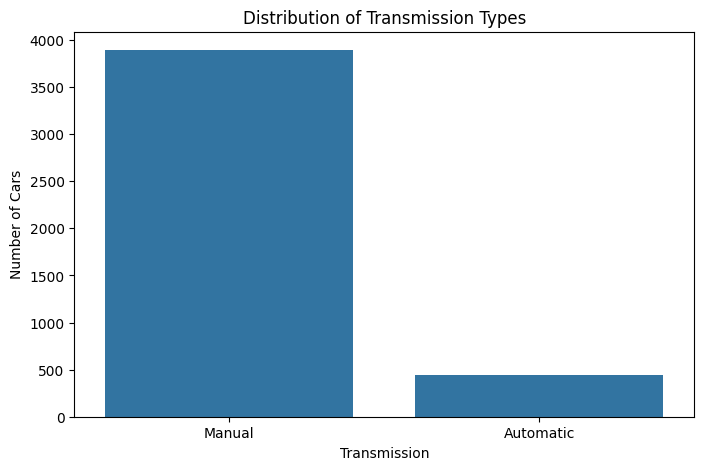

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='transmission'
)

plt.title("Distribution of Transmission Types")
plt.xlabel("Transmission")
plt.ylabel("Number of Cars")

plt.show()

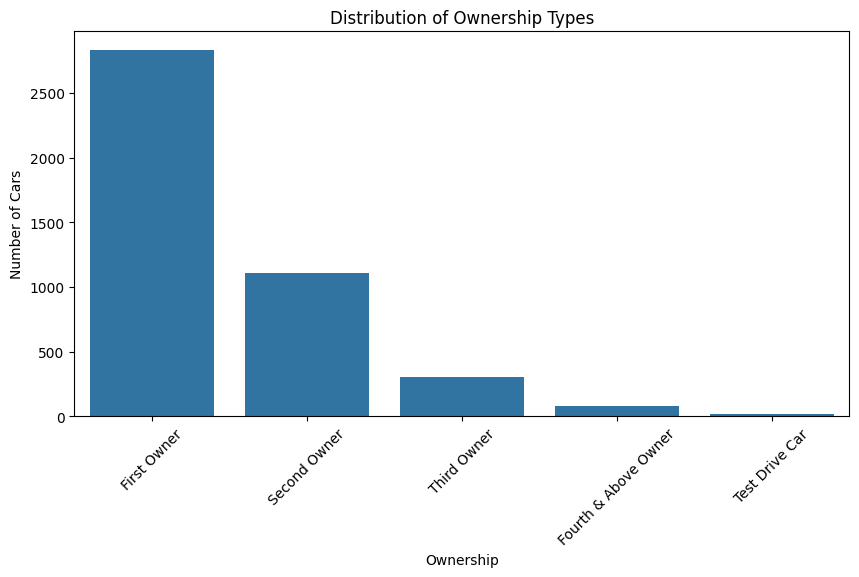

In [24]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='owner',
    order=df['owner'].value_counts().index
)

plt.title("Distribution of Ownership Types")
plt.xlabel("Ownership")
plt.ylabel("Number of Cars")

plt.xticks(rotation=45)

plt.show()

## Numerical Feature Analysis

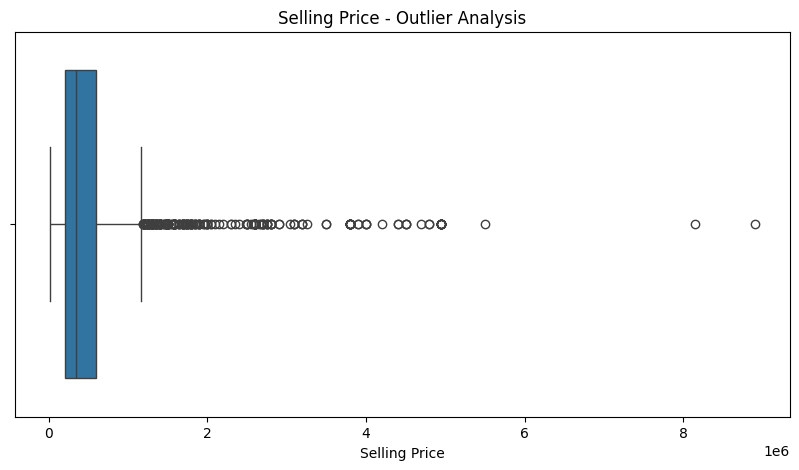

In [25]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df['selling_price']
)

plt.title("Selling Price - Outlier Analysis")
plt.xlabel("Selling Price")

plt.show()

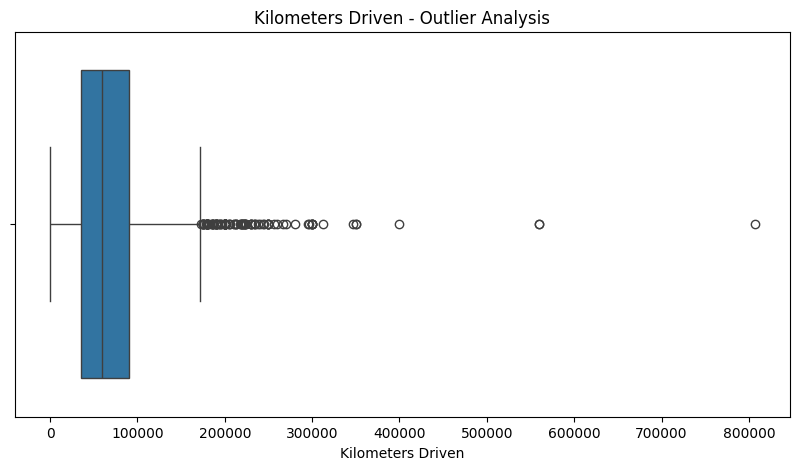

In [26]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df['km_driven']
)

plt.title("Kilometers Driven - Outlier Analysis")
plt.xlabel("Kilometers Driven")

plt.show()

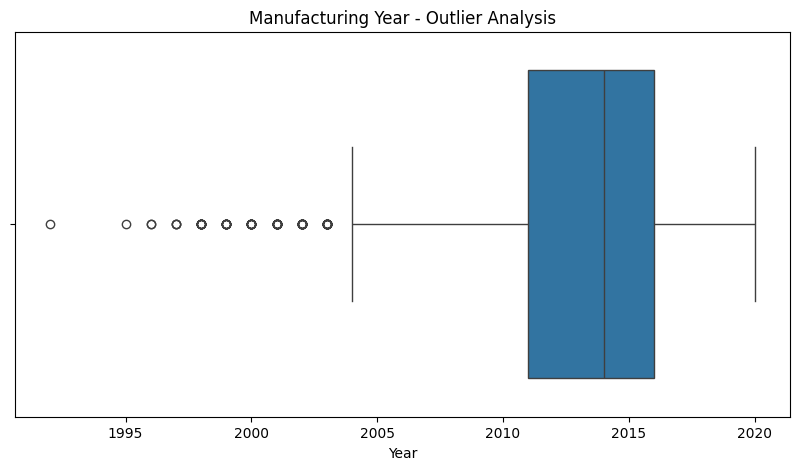

In [27]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df['year']
)

plt.title("Manufacturing Year - Outlier Analysis")
plt.xlabel("Year")

plt.show()

## Categorical Feature Analysis

In [28]:
for col in categorical_cols:

    print("\nFeature:", col)

    print(df[col].value_counts())


Feature: name
name
Maruti Swift Dzire VDI                      69
Maruti Alto 800 LXI                         59
Maruti Alto LXi                             47
Maruti Alto LX                              35
Hyundai EON Era Plus                        35
                                            ..
Honda Jazz Select Edition                    1
Maruti Swift Dzire AMT VXI                   1
Hyundai Creta 1.6 SX Automatic               1
Mercedes-Benz E-Class 280 CDI Elegance       1
Audi RS7 2015-2019 Sportback Performance     1
Name: count, Length: 1491, dtype: int64

Feature: fuel
fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64

Feature: seller_type
seller_type
Individual          3244
Dealer               994
Trustmark Dealer     102
Name: count, dtype: int64

Feature: transmission
transmission
Manual       3892
Automatic     448
Name: count, dtype: int64

Feature: owner
owner
First Owner             2832
Second O

### In Percentage

In [29]:
for col in categorical_cols:

    print("\nFeature:", col)

    print(
        df[col].value_counts(normalize=True) * 100
    )


Feature: name
name
Maruti Swift Dzire VDI                      1.589862
Maruti Alto 800 LXI                         1.359447
Maruti Alto LXi                             1.082949
Maruti Alto LX                              0.806452
Hyundai EON Era Plus                        0.806452
                                              ...   
Honda Jazz Select Edition                   0.023041
Maruti Swift Dzire AMT VXI                  0.023041
Hyundai Creta 1.6 SX Automatic              0.023041
Mercedes-Benz E-Class 280 CDI Elegance      0.023041
Audi RS7 2015-2019 Sportback Performance    0.023041
Name: proportion, Length: 1491, dtype: float64

Feature: fuel
fuel
Diesel      49.608295
Petrol      48.917051
CNG          0.921659
LPG          0.529954
Electric     0.023041
Name: proportion, dtype: float64

Feature: seller_type
seller_type
Individual          74.746544
Dealer              22.903226
Trustmark Dealer     2.350230
Name: proportion, dtype: float64

Feature: transmission
transmi

## Bivariate Analysis

### A. Numerical vs Numerical

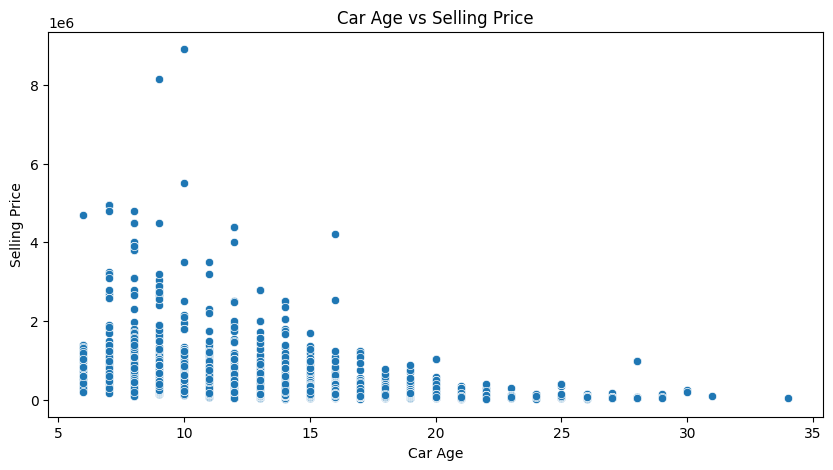

In [30]:
current_year = 2026

df['car_age'] = current_year - df['year']

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='car_age',
    y='selling_price'
)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age")
plt.ylabel("Selling Price")

plt.show()

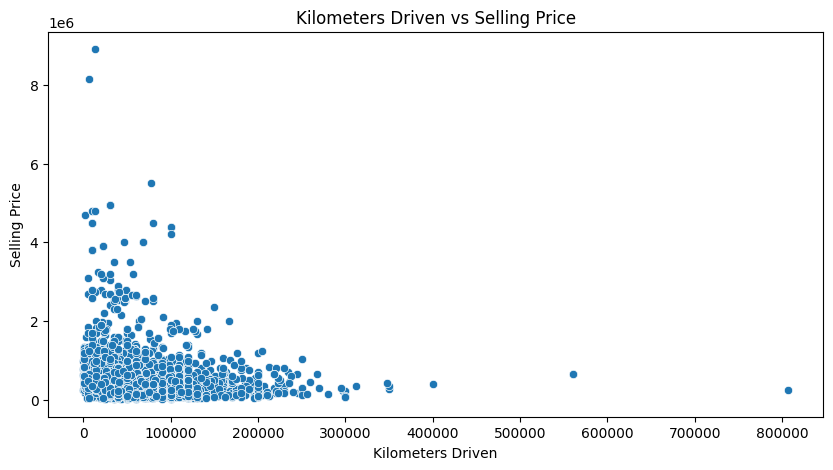

In [31]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='km_driven',
    y='selling_price'
)

plt.title("Kilometers Driven vs Selling Price")
plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price")

plt.show()

### B. Categorical vs Numerical

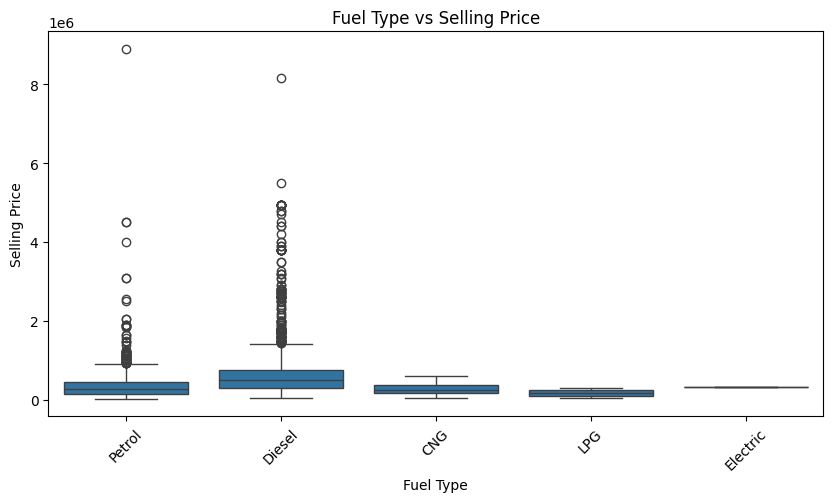

In [32]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='fuel',
    y='selling_price'
)

plt.title("Fuel Type vs Selling Price")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")

plt.xticks(rotation=45)

plt.show()

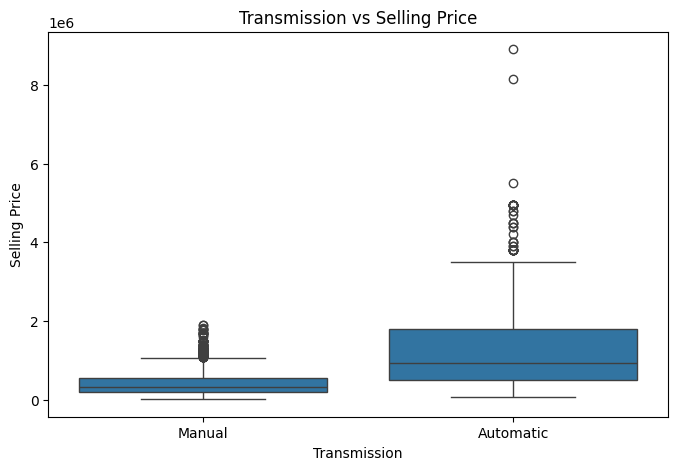

In [33]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='transmission',
    y='selling_price'
)

plt.title("Transmission vs Selling Price")
plt.xlabel("Transmission")
plt.ylabel("Selling Price")

plt.show()

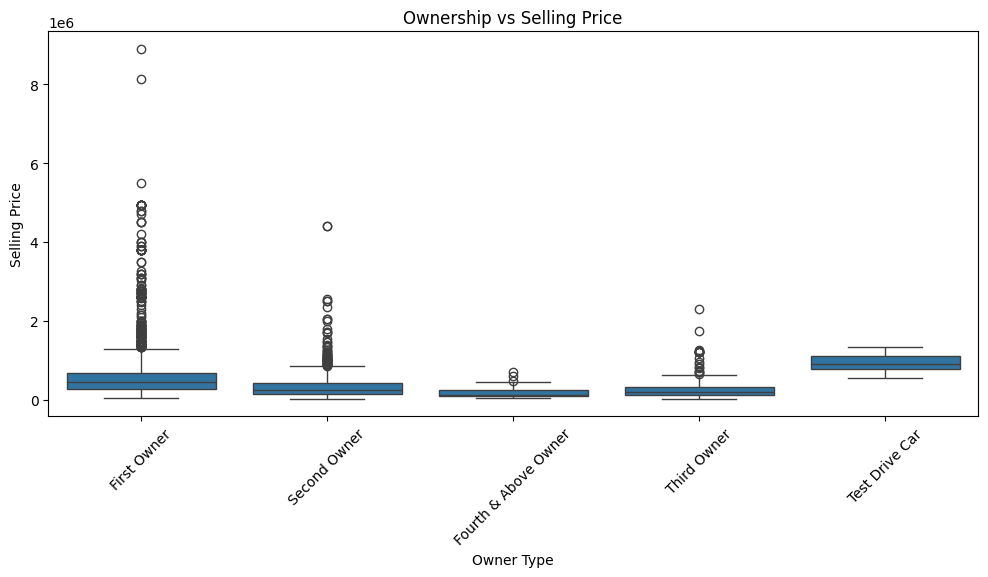

In [34]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df,
    x='owner',
    y='selling_price'
)

plt.title("Ownership vs Selling Price")
plt.xlabel("Owner Type")
plt.ylabel("Selling Price")

plt.xticks(rotation=45)

plt.show()

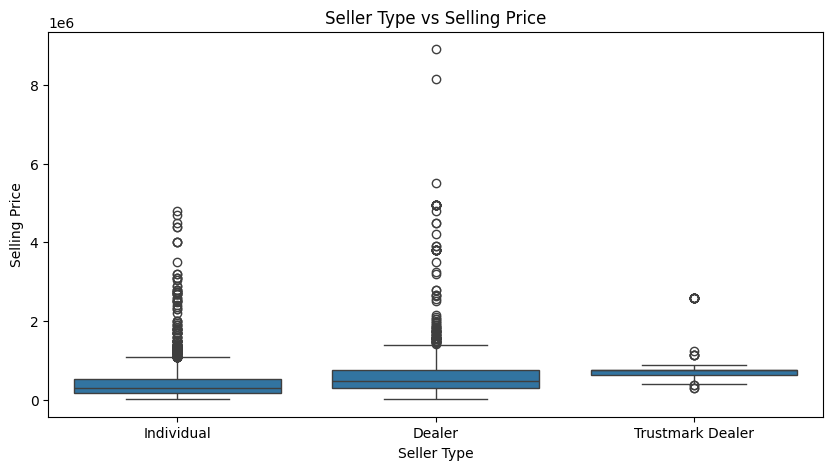

In [35]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='seller_type',
    y='selling_price'
)

plt.title("Seller Type vs Selling Price")
plt.xlabel("Seller Type")
plt.ylabel("Selling Price")

plt.show()

## Multivariate Analysis

## Fuel type, car age and selling price

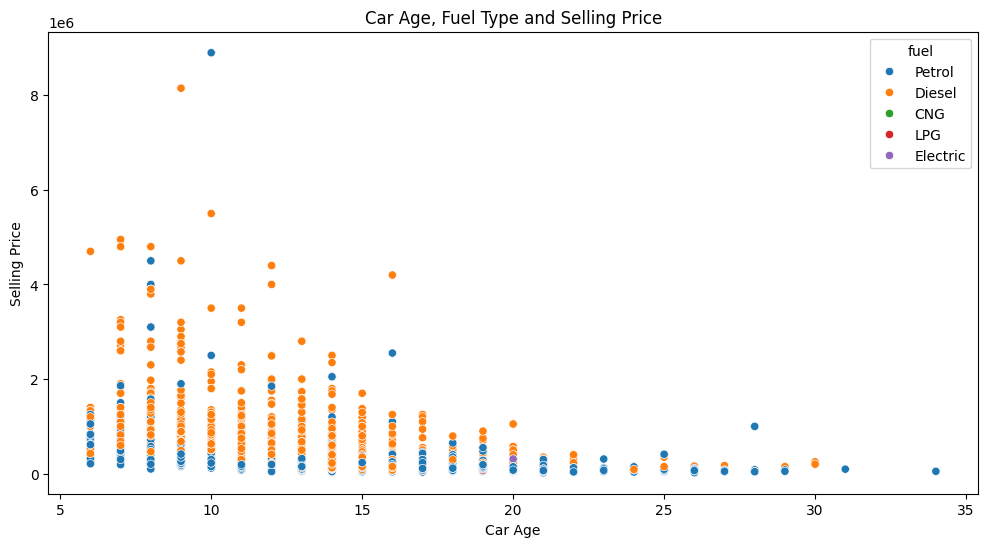

In [36]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x='car_age',
    y='selling_price',
    hue='fuel'
)

plt.title("Car Age, Fuel Type and Selling Price")
plt.xlabel("Car Age")
plt.ylabel("Selling Price")

plt.show()

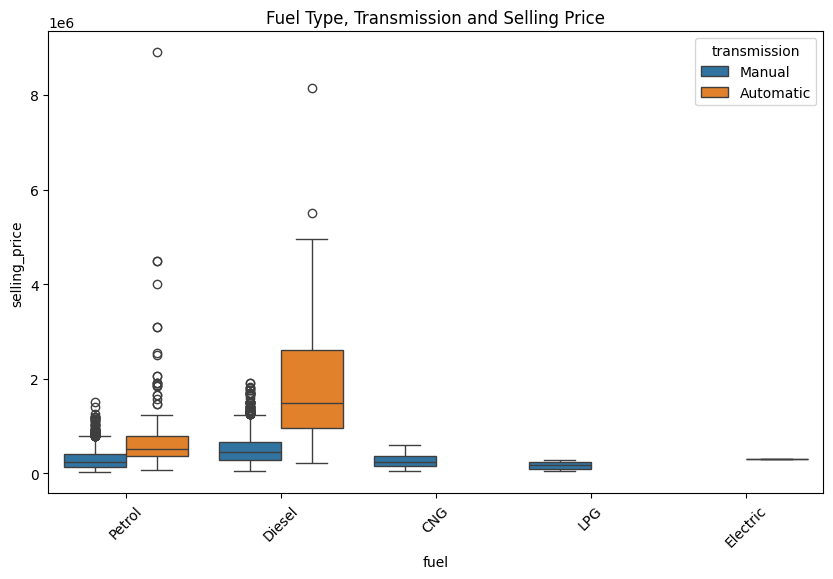

In [37]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='fuel',
    y='selling_price',
    hue='transmission'
)

plt.title("Fuel Type, Transmission and Selling Price")

plt.xticks(rotation=45)

plt.show()

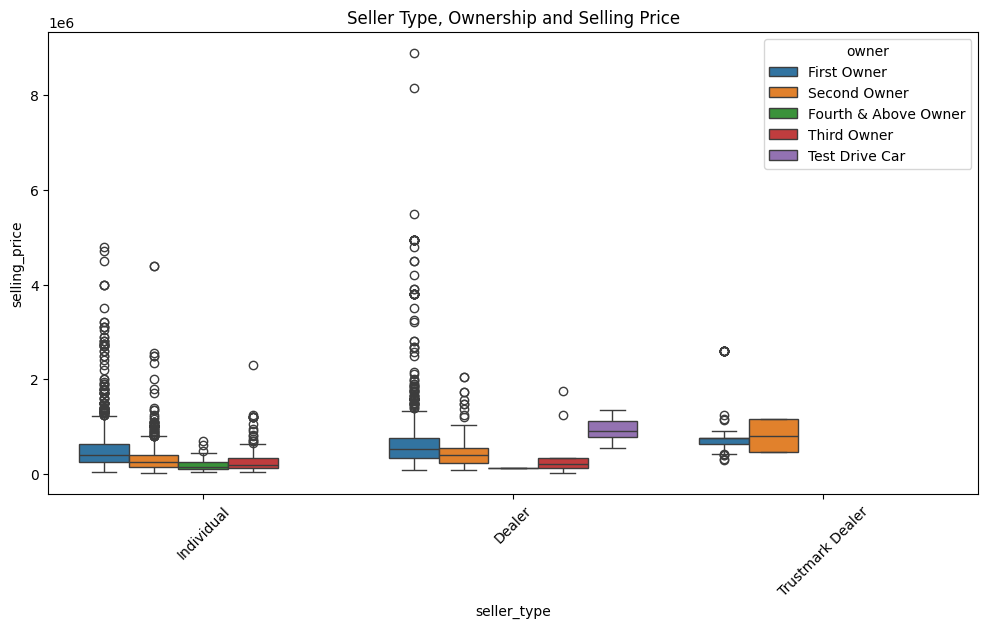

In [38]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='seller_type',
    y='selling_price',
    hue='owner'
)

plt.title("Seller Type, Ownership and Selling Price")

plt.xticks(rotation=45)

plt.show()

## Correlation Analysis

In [39]:
correlation_matrix = df.select_dtypes(
    include=np.number
).corr()

correlation_matrix

,year,selling_price,km_driven,car_age
year,1.000000,0.413922,-0.419688,-1.000000
selling_price,0.413922,1.000000,-0.192289,-0.413922
km_driven,-0.419688,-0.192289,1.000000,0.419688
car_age,-1.000000,-0.413922,0.419688,1.000000


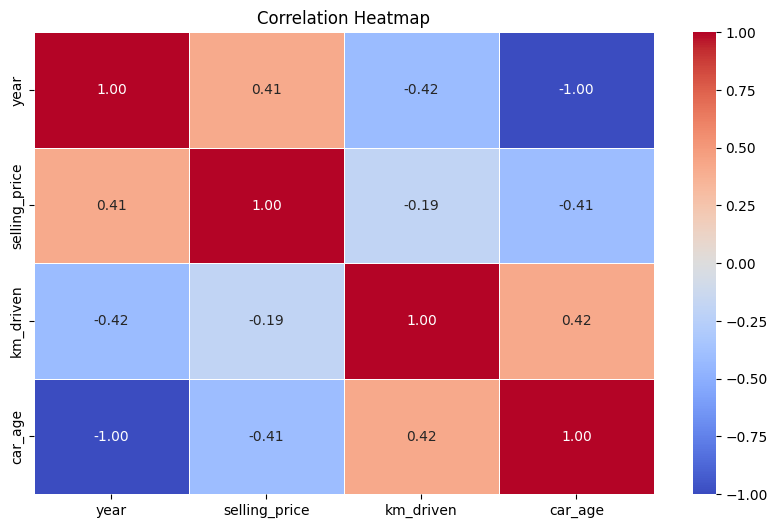

In [40]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.show()

# Data Cleaning & Preprocessing

In [41]:
import pandas as pd
import numpy as np

# Load original dataset
df = pd.read_csv("/content/CAR DETAILS FROM CAR DEKHO.csv")

# Create a working copy
data = df.copy()

# Display first five records
data.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [42]:
print("Numerical Columns:")
print(data.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Columns:")
print(data.select_dtypes(include='object').columns.tolist())

Numerical Columns:
['year', 'selling_price', 'km_driven']

Categorical Columns:
['name', 'fuel', 'seller_type', 'transmission', 'owner']


## check for missing values

In [43]:
data.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


## Remove Duplicate Records

In [44]:
print("Duplicate Records:", data.duplicated().sum())

Duplicate Records: 763


In [45]:
data = data.drop_duplicates()

In [46]:
data = data.reset_index(drop=True)

In [47]:
print("Remaining Duplicates:", data.duplicated().sum())

print("Updated Shape:", data.shape)

Remaining Duplicates: 0
Updated Shape: (3577, 8)


In [48]:
categorical_cols = data.select_dtypes(
    include='object'
).columns

for col in categorical_cols:
    data[col] = data[col].str.strip()

## Detect and Handle Outliers

### Calculate IQR

In [49]:
Q1 = data['selling_price'].quantile(0.25)

Q3 = data['selling_price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -400000.0
Upper Bound: 1200000.0


### Identify outliers

In [50]:
outliers = data[
    (data['selling_price'] < lower_bound) |
    (data['selling_price'] > upper_bound)
]

print("Number of Outliers:", len(outliers))

Number of Outliers: 170


### Vizualize outliers

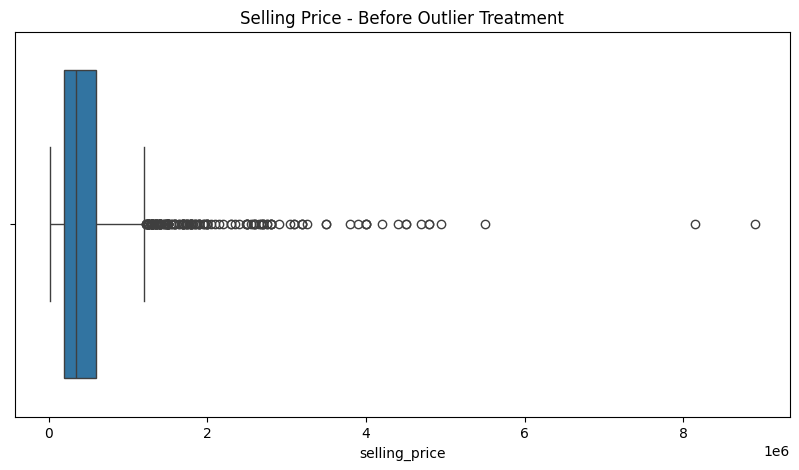

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.boxplot(x=data['selling_price'])

plt.title("Selling Price - Before Outlier Treatment")

plt.show()

### Handle outliers using capping

In [52]:
data['selling_price'] = data['selling_price'].clip(
    lower=lower_bound,
    upper=upper_bound
)

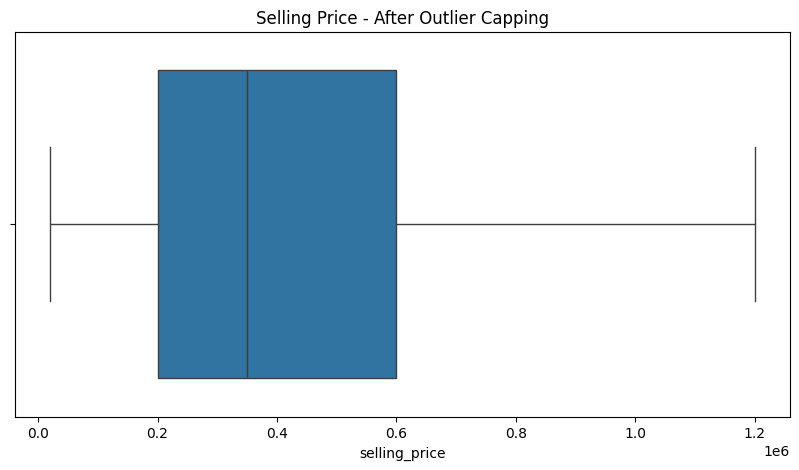

In [53]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=data['selling_price'])

plt.title("Selling Price - After Outlier Capping")

plt.show()

## Encode Categorical Variables

In [54]:
categorical_cols = data.select_dtypes(
    include='object'
).columns

print(categorical_cols)

Index(['name', 'fuel', 'seller_type', 'transmission', 'owner'], dtype='object')


### Apply one hot encoding

In [55]:
encoded_data = pd.get_dummies(
    data,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

encoded_data.head()

,year,selling_price,km_driven,name_Ambassador Classic 2000 Dsz,name_Ambassador Grand 1800 ISZ MPFI PW CL,name_Audi A4 1.8 TFSI,name_Audi A4 2.0 TDI,name_Audi A4 2.0 TDI 177 Bhp Premium Plus,name_Audi A4 3.0 TDI Quattro,name_Audi A4 30 TFSI Technology,...,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,2007,60000,70000,0,0,0,0,0,0,0,...,0,0,1,1,0,1,0,0,0,0
1,2007,135000,50000,0,0,0,0,0,0,0,...,0,0,1,1,0,1,0,0,0,0
2,2012,600000,100000,0,0,0,0,0,0,0,...,0,0,0,1,0,1,0,0,0,0
3,2017,250000,46000,0,0,0,0,0,0,0,...,0,0,1,1,0,1,0,0,0,0
4,2014,450000,141000,0,0,0,0,0,0,0,...,0,0,0,1,0,1,0,1,0,0


## Feature Scaling

### Apply StandardScaler

In [56]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

numerical_features = [
    'year',
    'km_driven'
]

scaled_data = data.copy()

scaled_data[numerical_features] = scaler.fit_transform(
    scaled_data[numerical_features]
)

scaled_data.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,-1.402566,60000,0.015754,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,-1.402566,135000,-0.404650,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,-0.226418,600000,0.646360,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,0.949731,250000,-0.488731,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,0.244042,450000,1.508188,Diesel,Individual,Manual,Second Owner


## Train-Test Split

In [57]:
X = data.drop('selling_price', axis=1)

y = data['selling_price']

In [58]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [59]:
print("Training Features:", X_train.shape)

print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)

print("Testing Target:", y_test.shape)

Training Features: (2861, 7)
Testing Features: (716, 7)
Training Target: (2861,)
Testing Target: (716,)


## Feature Engineering & Feature Selection

In [143]:
# Extract brand
data['brand'] = data['name'].str.split().str[0]

# Extract model
data['model'] = data['name'].str.split().str[1]

# Display extracted features
data[['name', 'brand', 'model']].head(10)

,name,brand,model
0,Maruti 800 AC,Maruti,800
1,Maruti Wagon R LXI Minor,Maruti,Wagon
2,Hyundai Verna 1.6 SX,Hyundai,Verna
3,Datsun RediGO T Option,Datsun,RediGO
4,Honda Amaze VX i-DTEC,Honda,Amaze
5,Maruti Alto LX BSIII,Maruti,Alto
6,Hyundai Xcent 1.2 Kappa S,Hyundai,Xcent
7,Tata Indigo Grand Petrol,Tata,Indigo
8,Hyundai Creta 1.6 VTVT S,Hyundai,Creta
9,Maruti Celerio Green VXI,Maruti,Celerio


In [144]:
# Calculate car age
CURRENT_YEAR = 2026

data['car_age'] = CURRENT_YEAR - data['year']

# Display results
data[['year', 'car_age']].head(10)

,year,car_age
0,2007,19
1,2007,19
2,2012,14
3,2017,9
4,2014,12
5,2007,19
6,2016,10
7,2014,12
8,2015,11
9,2017,9


In [145]:
# Create car age categories
data['car_age_category'] = pd.cut(
    data['car_age'],
    bins=[-1, 3, 7, 12, np.inf],
    labels=['New', 'Moderate', 'Old', 'Very Old']
)

# Check the results
data[['car_age', 'car_age_category']].head(10)

,car_age,car_age_category
0,19,Very Old
1,19,Very Old
2,14,Very Old
3,9,Old
4,12,Old
5,19,Very Old
6,10,Old
7,12,Old
8,11,Old
9,9,Old


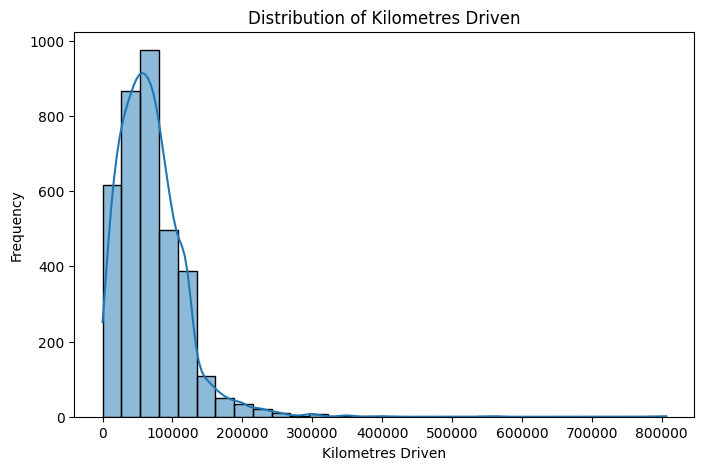

In [146]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(data['km_driven'], bins=30, kde=True)

plt.title('Distribution of Kilometres Driven')
plt.xlabel('Kilometres Driven')
plt.ylabel('Frequency')

plt.show()

In [147]:
# Log transformation
data['km_driven_log'] = np.log1p(data['km_driven'])

# Compare original and transformed values
data[['km_driven', 'km_driven_log']].head(10)

,km_driven,km_driven_log
0,70000,11.156265
1,50000,10.819798
2,100000,11.512935
3,46000,10.736418
4,141000,11.856522
5,125000,11.736077
6,25000,10.126671
7,60000,11.002117
8,25000,10.126671
9,78000,11.264477


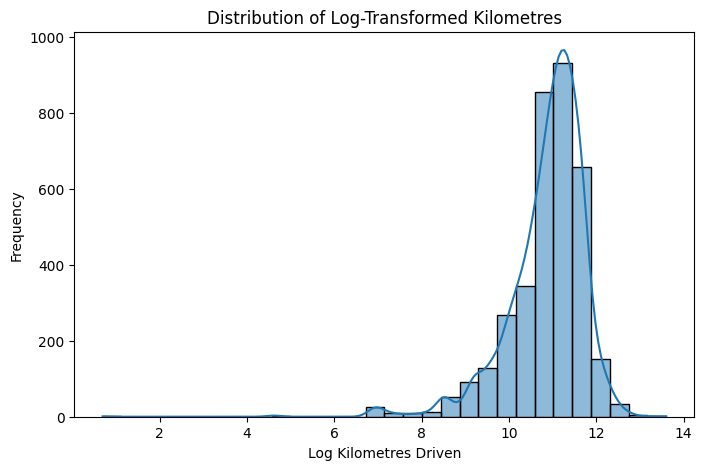

In [148]:
plt.figure(figsize=(8, 5))

sns.histplot(data['km_driven_log'], bins=30, kde=True)

plt.title('Distribution of Log-Transformed Kilometres')
plt.xlabel('Log Kilometres Driven')
plt.ylabel('Frequency')

plt.show()

In [149]:
brand_counts = data['brand'].value_counts()

print("Total Unique Brands:", data['brand'].nunique())

print("\nTop 15 Brands:")
print(brand_counts.head(15))

Total Unique Brands: 29

Top 15 Brands:
brand
Maruti        1072
Hyundai        637
Mahindra       328
Tata           308
Ford           220
Honda          216
Toyota         170
Chevrolet      151
Renault        110
Volkswagen      93
Nissan          52
Skoda           49
Fiat            32
Audi            31
Datsun          29
Name: count, dtype: int64


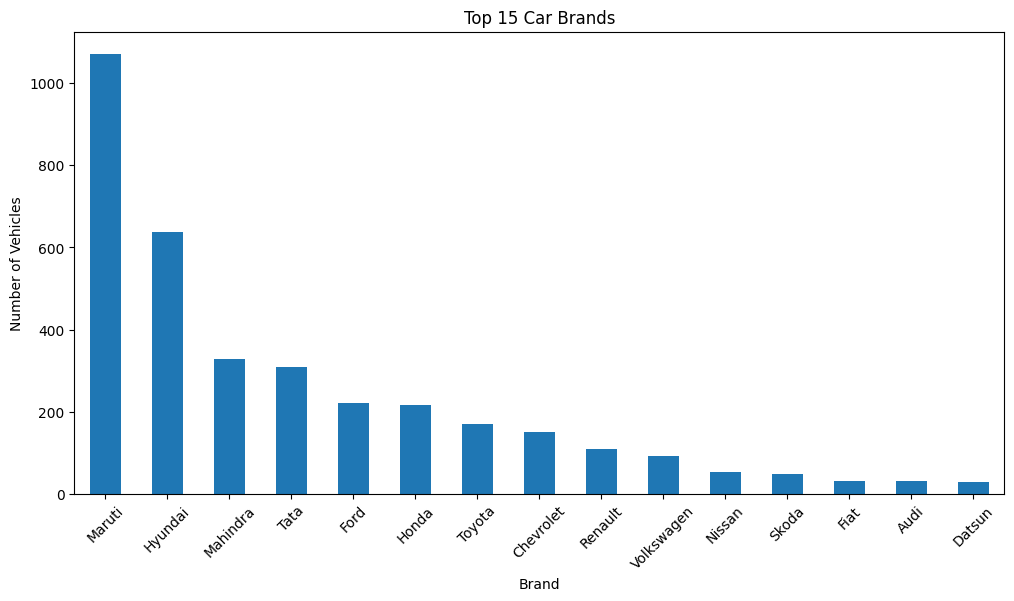

In [150]:
plt.figure(figsize=(12, 6))

brand_counts.head(15).plot(kind='bar')

plt.title('Top 15 Car Brands')
plt.xlabel('Brand')
plt.ylabel('Number of Vehicles')
plt.xticks(rotation=45)

plt.show()

In [151]:
model_counts = data['model'].value_counts()

print("Total Unique Models:", data['model'].nunique())

print("\nTop 20 Models:")
print(model_counts.head(20))

Total Unique Models: 185

Top 20 Models:
model
Swift      270
Alto       228
Wagon      139
i20        113
Verna      103
Innova      89
Indica      86
Scorpio     85
Santro      84
City        80
Figo        80
Grand       77
EON         77
XUV500      64
i10         60
Bolero      59
Beat        56
KWID        55
Zen         51
800         51
Name: count, dtype: int64


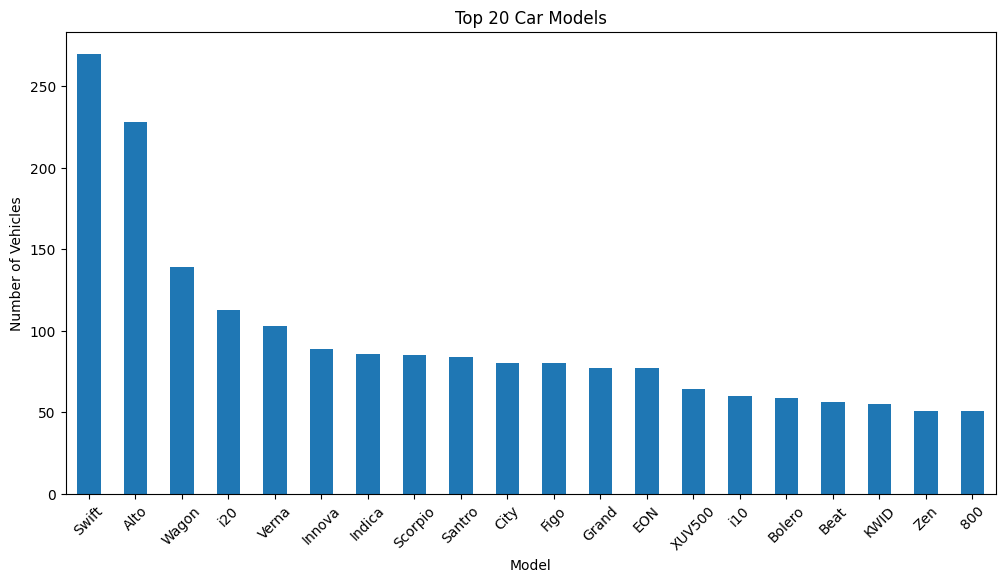

In [152]:
plt.figure(figsize=(12, 6))

model_counts.head(20).plot(kind='bar')

plt.title('Top 20 Car Models')
plt.xlabel('Model')
plt.ylabel('Number of Vehicles')
plt.xticks(rotation=45)

plt.show()

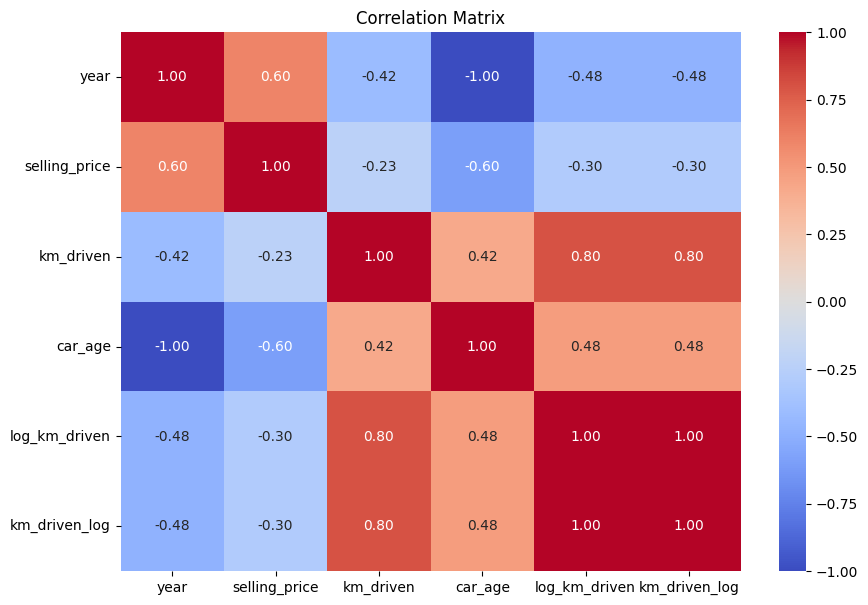

In [153]:
numerical_data = data.select_dtypes(include=np.number)

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')

plt.show()

In [154]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Select features for importance analysis
importance_features = [
    'brand',
    'model',
    'car_age',
    'km_driven',
    'fuel',
    'seller_type',
    'transmission',
    'owner'
]

X = data[importance_features].copy()
y = data['selling_price'].copy()

numerical_features = ['car_age', 'km_driven']

categorical_features = [
    'brand',
    'model',
    'fuel',
    'seller_type',
    'transmission',
    'owner'
]

preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numerical_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Transform training data only
X_train_transformed = preprocessor.fit_transform(X_train)

# Train Random Forest for feature importance
rf_importance = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_importance.fit(X_train_transformed, y_train)

RandomForestRegressor(max_depth=15, min_samples_leaf=2, min_samples_split=5,
                      n_estimators=200, n_jobs=-1, random_state=42)

In [155]:
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_importance.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df.head(20))

                         Feature  Importance
0                   num__car_age    0.421326
202             cat__fuel_Diesel    0.113085
209     cat__transmission_Manual    0.074931
208  cat__transmission_Automatic    0.063812
1                 num__km_driven    0.053778
109            cat__model_Innova    0.027458
26             cat__brand_Toyota    0.025337
191            cat__model_XUV500    0.017214
42               cat__model_Alto    0.011352
25               cat__brand_Tata    0.011143
65               cat__model_City    0.010528
70              cat__model_Creta    0.010286
204             cat__fuel_Petrol    0.010286
158           cat__model_Scorpio    0.006642
92           cat__model_Fortuner    0.006325
179             cat__model_Verna    0.006080
18             cat__brand_Maruti    0.005829
11              cat__brand_Honda    0.005621
3                cat__brand_Audi    0.004969
24              cat__brand_Skoda    0.004725


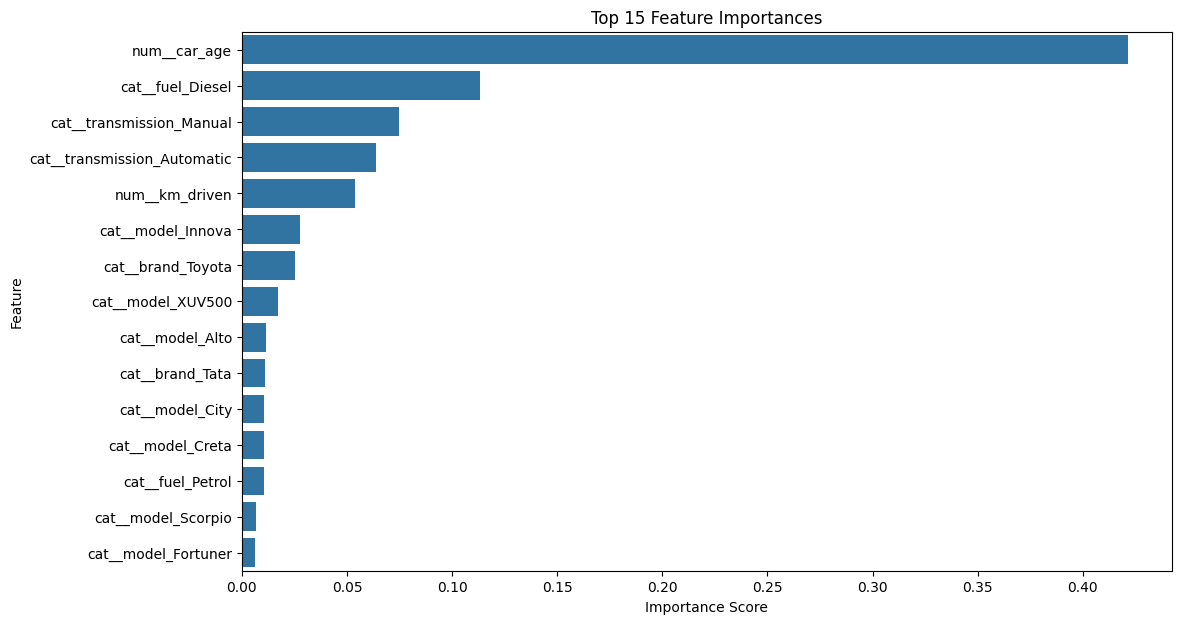

In [156]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Feature Importances')
plt.xlabel('Importance Score')
plt.ylabel('Feature')

plt.show()

In [157]:
selected_features = [
    'brand',
    'model',
    'car_age',
    'km_driven',
    'fuel',
    'seller_type',
    'transmission',
    'owner'
]

X = data[selected_features].copy()

y = data['selling_price'].copy()

print("Selected Features:")
print(selected_features)

print("\nFeature Matrix Shape:", X.shape)

print("\nTarget Shape:", y.shape)

Selected Features:
['brand', 'model', 'car_age', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

Feature Matrix Shape: (3577, 8)

Target Shape: (3577,)


In [158]:
y = data['selling_price']

In [161]:
# Save engineered dataset
data.to_csv('engineered_car_data.csv',
    index=False
)

print("Engineered dataset saved successfully!")

Engineered dataset saved successfully!


In [162]:
print("Final Dataset Shape:", data.shape)

print("\nFinal Columns:")
print(data.columns.tolist())

print("\nSelected Features:")
print(X.columns.tolist())

Final Dataset Shape: (3577, 15)

Final Columns:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'brand', 'car_age', 'usage_category', 'log_km_driven', 'model', 'car_age_category', 'km_driven_log']

Selected Features:
['brand', 'model', 'car_age', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


Dataset Loading: Loaded the Car dataset.



Brand Extraction: Extracted the car brand from the original name column.



Model Extraction: Extracted the car model from the original name column.



Car Age Calculation: Created a new car_age feature using the manufacturing year and reference year 2026.



Age Categorisation: Categorised vehicles into New, Moderate, Old and Very Old.



Log Transformation: Applied log1p() to km_driven to reduce the effect of skewness.



Brand Distribution Analysis: Analysed the frequency and distribution of different car brands.



Model Distribution Analysis: Identified 185 unique car models and analysed their frequency.



Correlation Analysis: Examined relationships between numerical features and selling price using a correlation matrix.



Feature Importance Analysis: Used Random Forest feature importance to understand the contribution of different features.



Feature Selection: Finalised eight input features for predicting car selling prices.



Dataset Export: Saved the engineered dataset as engineered_car_data.csv.

## Model Building, Training and Evaluation

Implemente five regression algorithms:
- Linear Regression
- Decision Tree Regressor
- Random Forest Regressor
- Gradient Boosting Regressor
- XGBoost Regressor

In [164]:
selected_features = [
    'brand',
    'model',
    'car_age',
    'km_driven',
    'fuel',
    'seller_type',
    'transmission',
    'owner'
]

X = data[selected_features].copy()

y = data['selling_price'].copy()

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

Input Features Shape: (3577, 8)
Target Variable Shape: (3577,)


In [165]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (2861, 8)
Testing Data: (716, 8)


In [166]:
numerical_features = [
    'car_age',
    'km_driven'
]

categorical_features = [
    'brand',
    'model',
    'fuel',
    'seller_type',
    'transmission',
    'owner'
]

In [167]:
numerical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

In [169]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    'XGBoost': XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1
    )
}

In [170]:
trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    model_pipeline = Pipeline([
        ('preprocessor', Pipeline([
            ('transformer', preprocessor)
        ])),
        ('regressor', model)
    ])

    model_pipeline.fit(X_train, y_train)

    trained_models[name] = model_pipeline

    print(f"{name} training completed!\n")

Training Linear Regression...
Linear Regression training completed!

Training Decision Tree...
Decision Tree training completed!

Training Random Forest...
Random Forest training completed!

Training Gradient Boosting...
Gradient Boosting training completed!

Training XGBoost...
XGBoost training completed!



In [171]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='RMSE',
    ascending=True
)

results_df

,Model,MAE,MSE,RMSE,R2 Score
4,XGBoost,86457.515625,1.529359e+10,123667.257300,0.835088
0,Linear Regression,91552.563892,1.692785e+10,130107.052780,0.817465
2,Random Forest,88728.603084,1.775467e+10,133246.652039,0.808549
3,Gradient Boosting,103820.465590,1.984922e+10,140887.253264,0.785964
1,Decision Tree,109161.669435,2.590394e+10,160947.014478,0.720675


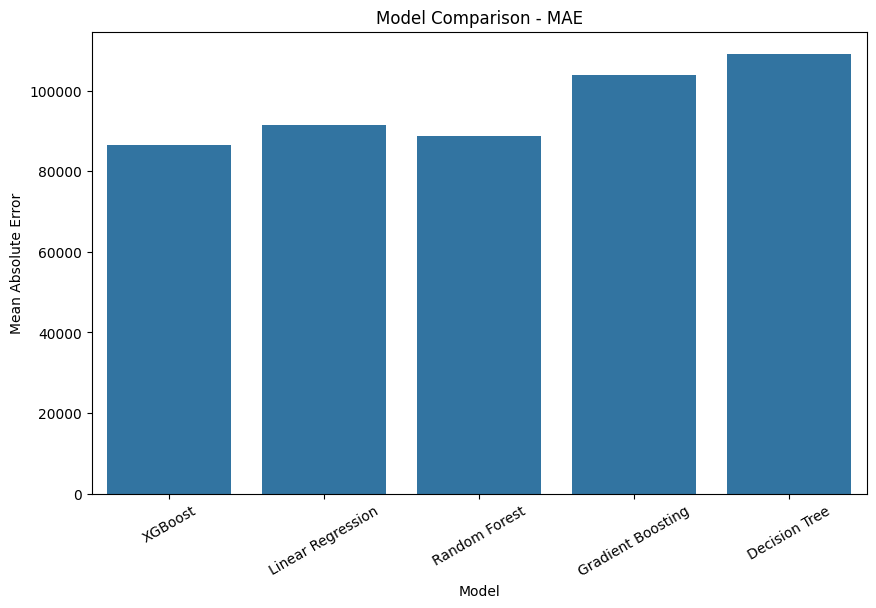

In [172]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='MAE'
)

plt.title('Model Comparison - MAE')
plt.xticks(rotation=30)
plt.ylabel('Mean Absolute Error')

plt.show()

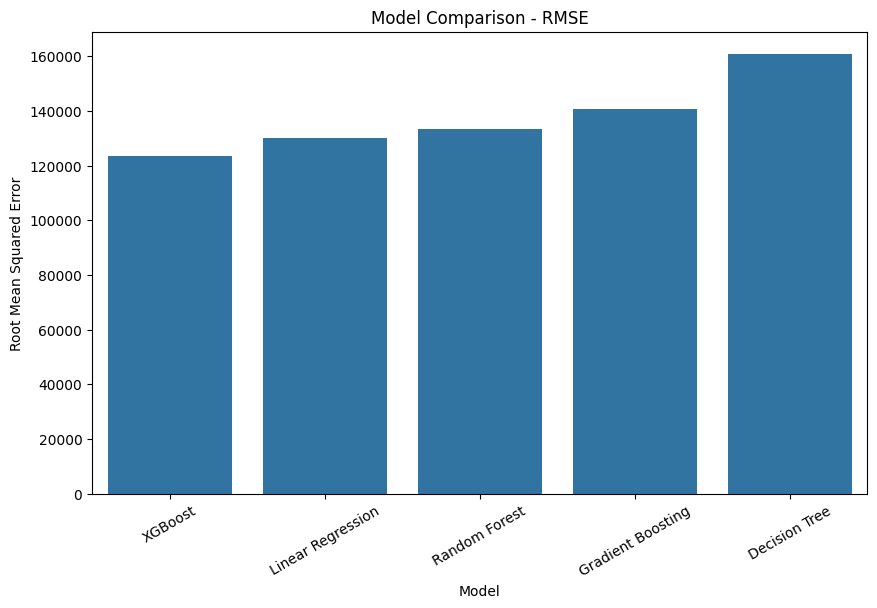

In [173]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE'
)

plt.title('Model Comparison - RMSE')
plt.xticks(rotation=30)
plt.ylabel('Root Mean Squared Error')

plt.show()

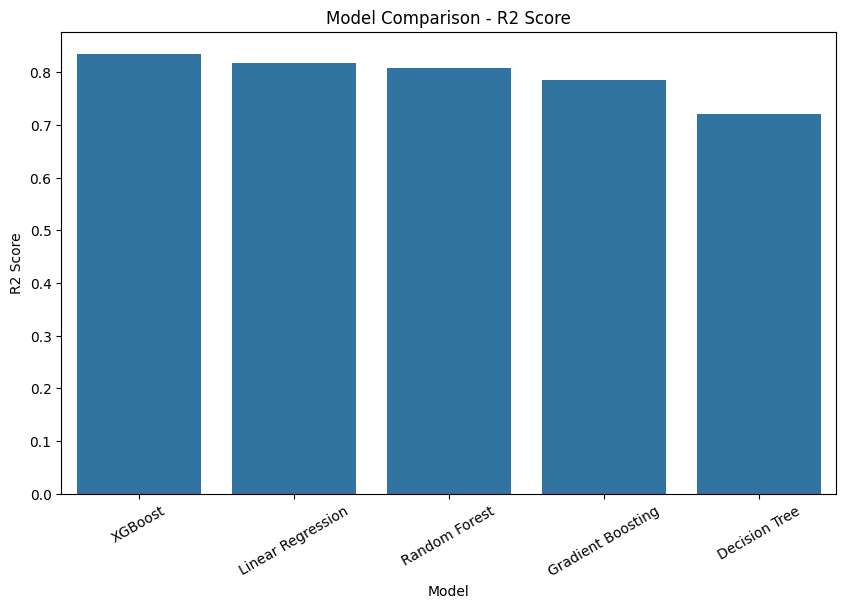

In [174]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score'
)

plt.title('Model Comparison - R2 Score')
plt.xticks(rotation=30)
plt.ylabel('R2 Score')

plt.show()

In [175]:
best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

print("Best Performing Model:", best_model_name)

print("\nBest Model Evaluation:")
print(results_df.iloc[0])

Best Performing Model: XGBoost

Best Model Evaluation:
Model             XGBoost
MAE          86457.515625
MSE         15293590528.0
RMSE          123667.2573
R2 Score         0.835088
Name: 4, dtype: object


In [178]:
joblib.dump(
    best_model,
    '../models/best_car_price_model.pkl'
)

print("Best model saved successfully!")

Best model saved successfully!


## Tested predictions for individual cars

In [191]:
sample_car = X_test.iloc[[10]]

actual_price = y_test.iloc[10]

predicted_price = best_model.predict(sample_car)[0]

print(f"Actual Selling Price: ₹{actual_price:,.2f}")

print(f"Predicted Selling Price: ₹{predicted_price:,.2f}")

Actual Selling Price: ₹250,000.00
Predicted Selling Price: ₹214,998.19
